# Unit 8 code companion: Probability as a Model

Choose a distribution, fit it, check it, and use it to answer a question the data alone cannot. The last third turns Unit 4's prediction interval back into the distribution it came from. Short cells, meant to be run one at a time.

Run the cells in order. Each section matches a moment in the slides. The point is to see the mechanism move when you change the inputs, so change them.

## Setup



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from scipy.stats import binom, poisson, norm, lognorm

jobs = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/moving_jobs.csv")
jobs.head()

,hours,volume_cuft,crew_size,miles,stairs_flights,packing_service,weekend,est_boxes,dispatcher_rating,quote_source,truck_id
0,7.83,557,3,7.9,1,0,0,37,5,web,T-5
1,10.88,662,2,23.6,2,0,1,51,5,web,T-4
2,16.00,1066,3,3.9,4,0,1,101,2,phone,T-2
3,11.37,845,2,4.7,0,0,0,76,2,referral,T-5
4,7.37,339,3,5.7,2,1,0,21,3,web,T-3


## 1. Three columns, three kinds of outcome

Nothing is fitted yet. The question is what kind of thing each column is.

In [2]:
jobs[["weekend", "stairs_flights", "est_boxes", "hours"]].describe().round(2)

,weekend,stairs_flights,est_boxes,hours
count,600.00,600.00,600.00,600.00
mean,0.27,1.17,58.95,10.43
std,0.45,1.09,19.96,2.94
min,0.00,0.00,4.00,3.48
25%,0.00,0.00,46.00,8.25
50%,0.00,1.00,58.00,10.31
75%,1.00,2.00,73.00,12.27
max,1.00,6.00,119.00,19.97


`weekend` is a yes or no, repeated 600 times: **binomial**. `stairs_flights` and `est_boxes` are counts with no fixed ceiling: **Poisson**, maybe. `hours` is a total made of loading, driving and unloading: **normal**, maybe. Two of those four guesses will survive the checking section.

## 2. Binomial: estimate p, then plan a week



In [3]:
n, x = len(jobs), jobs.weekend.sum()
p_hat = x / n
print(f"{x} of {n} jobs ran on a weekend, p-hat = {p_hat:.4f}")

bookings = 20
print(f"mean weekend jobs out of {bookings}:", round(bookings * p_hat, 2))
print("sd                            :", round(np.sqrt(bookings * p_hat * (1 - p_hat)), 2))
print("P(exactly 5)                  :", round(binom.pmf(5, bookings, p_hat), 3))
print("P(8 or more)                  :", round(binom.sf(7, bookings, p_hat), 3))

163 of 600 jobs ran on a weekend, p-hat = 0.2717
mean weekend jobs out of 20: 5.43
sd                            : 1.99
P(exactly 5)                  : 0.198
P(8 or more)                  : 0.15


The average is 5.43 and the plan has to cover more than the average. Change `bookings` to 50 and watch `P(8 or more)` stop being the interesting question.

## 3. Likelihood, on a grid

Score every candidate value of p, then take the best one.

In [4]:
p_grid = np.linspace(0.20, 0.35, 15001)
loglik = x * np.log(p_grid) + (n - x) * np.log1p(-p_grid)

print("the grid's best p:", round(p_grid[loglik.argmax()], 4))
print("163/600          :", round(x / n, 4))

the grid's best p: 0.2717
163/600          : 0.2717


Maximum likelihood did not invent a new estimator here. It arrived at the sample proportion, which is the point: the method agrees with what you would have done anyway in the easy cases, and keeps working in the hard ones.

## 4. Why software maximizes the log



In [5]:
print("the likelihood itself, at p-hat :", p_hat**163 * (1 - p_hat)**437)
print("the same thing with 10x the data:", p_hat**1630 * (1 - p_hat)**4370)
print("its log-likelihood              :",
      round(1630 * np.log(p_hat) + 4370 * np.log1p(-p_hat), 2))

the likelihood itself, at p-hat : 3.856712307265425e-153
the same thing with 10x the data: 0.0
its log-likelihood              : -3509.46


600 observations already put the likelihood at 4e-153. Ten times the data and the product is **exactly zero** in floating point, so the search has nothing to climb. The log is a sum, it never underflows, and it peaks in the same place.

## 5. The width of the peak

Two curves with the same p-hat and different amounts of information in them.

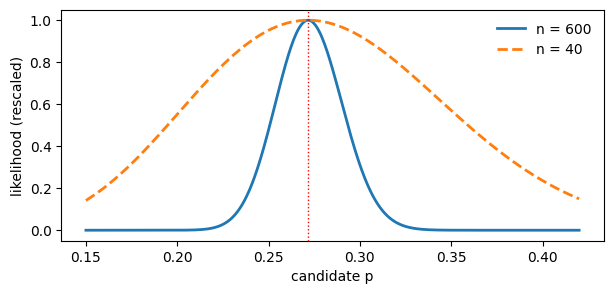

In [6]:
p = np.linspace(0.15, 0.42, 600)
fig, ax = plt.subplots(figsize=(7, 3))
for size, style in [(600, "-"), (40, "--")]:
    k = p_hat * size              # the same proportion, a smaller sample
    ll = k * np.log(p) + (size - k) * np.log1p(-p)
    ax.plot(p, np.exp(ll - ll.max()), style, lw=2, label=f"n = {size}")
ax.axvline(p_hat, color="red", lw=1, ls=":")
ax.set_xlabel("candidate p")
ax.set_ylabel("likelihood (rescaled)")
ax.legend(frameon=False)
plt.show()

A narrow peak means nearby values of p fit much worse, so the data have pinned the parameter down. A broad peak means they have not. That width is the standard error, and the next cell takes it out of the curve.

## 6. Curvature gives the standard error

A second derivative of the log-likelihood, computed numerically.

In [7]:
def loglik_at(q):
    return x * np.log(q) + (n - x) * np.log1p(-q)


h = 1e-4
curvature = (loglik_at(p_hat + h) - 2 * loglik_at(p_hat) + loglik_at(p_hat - h)) / h**2

print("SE from the curvature:", round(1 / np.sqrt(-curvature), 4))
print("SE from the formula  :", round(np.sqrt(p_hat * (1 - p_hat) / n), 4))
print("95% interval         :", np.round(p_hat + np.array([-1.96, 1.96]) *
                                         np.sqrt(p_hat * (1 - p_hat) / n), 4))

SE from the curvature: 0.0182
SE from the formula  : 0.0182
95% interval         : [0.2361 0.3073]


The two agree to four decimals. Unit 1 got a standard error from a formula and Unit 6 got one by resampling. This is the third route, and the only one of the three that works for a model whose formula nobody has worked out.

## 7. Poisson: the stairs rate



In [8]:
stairs = jobs.stairs_flights
lam = stairs.mean()

print("lambda-hat   :", round(lam, 3))
print("SE           :", round(np.sqrt(lam / n), 4))
print("P(no stairs) :", round(poisson.pmf(0, lam), 3), " observed:",
      round((stairs == 0).mean(), 3))
print("P(3 or more) :", round(poisson.sf(2, lam), 3), " observed:",
      round((stairs >= 3).mean(), 3))

lambda-hat   : 1.168
SE           : 0.0441
P(no stairs) : 0.311  observed: 0.312
P(3 or more) : 0.114  observed: 0.113


One number was fitted, the mean. The two probabilities underneath it were not fitted, and they come back right to three decimals. That is a check, not a coincidence.

## 8. Check it: observed against expected



In [9]:
def poisson_table(counts):
    lam = counts.mean()
    k = np.arange(0, counts.max() + 1)
    obs = np.array([(counts == i).sum() for i in k])
    exp = poisson.pmf(k, lam) * len(counts)
    exp[-1] += len(counts) * poisson.sf(k[-1], lam)   # last cell is "or more"
    return pd.DataFrame({"observed": obs, "expected": exp.round(1)}, index=k)


poisson_table(stairs)

,observed,expected
0,187,186.5
1,217,217.9
2,128,127.3
3,51,49.6
4,12,14.5
5,3,3.4
6,2,0.8


The last row is *6 or more*, which is why it reads 0.8 rather than the 0.7 that `poisson.pmf(6, lam) * 600` gives on its own. Two jobs where the model expected 0.8 is a big ratio and a small difference in jobs.

## 9. The variance-to-mean ratio

The cheapest check there is, and it needs no plot.

In [10]:
for name in ["stairs_flights", "est_boxes"]:
    col = jobs[name]
    print(f"{name:<15} mean {col.mean():8.3f}   variance {col.var():8.3f}"
          f"   ratio {col.var() / col.mean():6.2f}")

stairs_flights  mean    1.168   variance    1.182   ratio   1.01
est_boxes       mean   58.950   variance  398.512   ratio   6.76


A Poisson model has one variance available to it, equal to its mean. Stairs come in at 1.01 and are fine. Boxes come in at **6.8** and are not, and we knew that before drawing anything.

## 10. Overdispersion, and what it costs you

Fit Poisson to the boxes anyway and ask it about the busy jobs.

In [11]:
boxes = jobs.est_boxes
for threshold in [80, 90, 100]:
    print(f"more than {threshold} boxes:  observed {(boxes > threshold).mean():.4f}"
          f"   Poisson says {poisson.sf(threshold, boxes.mean()):.6f}")

more than 80 boxes:  observed 0.1417   Poisson says 0.003702
more than 90 boxes:  observed 0.0567   Poisson says 0.000065
more than 100 boxes:  observed 0.0250   Poisson says 0.000000


One job in eighteen needs more than 90 boxes. The fitted Poisson puts that at one in 15,000. Nothing errored, the estimate of lambda was correct, and a van loaded on this model would be short of boxes most weeks. Unit 9 comes back to this with quasi-Poisson and negative binomial.

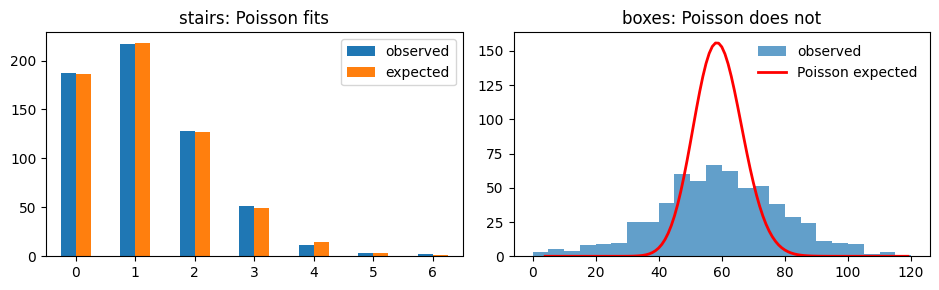

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3))
t = poisson_table(stairs)
t.plot.bar(ax=axes[0], rot=0, title="stairs: Poisson fits")
axes[1].hist(boxes, bins=np.arange(0, 125, 5), alpha=0.7, label="observed")
grid = np.arange(boxes.min(), boxes.max() + 1)
axes[1].plot(grid, poisson.pmf(grid, boxes.mean()) * len(boxes) * 5, "r-", lw=2,
             label="Poisson expected")
axes[1].set_title("boxes: Poisson does not")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 11. Normal: hours



In [13]:
hours = jobs.hours
mu, sigma = hours.mean(), hours.std()
print(f"mean {mu:.2f}   sd {sigma:.2f}   skew {hours.skew():.2f}")

z = (hours - mu) / sigma
print("within 1 sd:", round((z.abs() < 1).mean() * 100, 1), "%   (normal says 68.3)")
print("within 2 sd:", round((z.abs() < 2).mean() * 100, 1), "%   (normal says 95.4)")

mean 10.43   sd 2.94   skew 0.36
within 1 sd: 68.7 %   (normal says 68.3)
within 2 sd: 95.7 %   (normal says 95.4)


Unit 1 used 68-95-99.7 without saying where it came from. It came from here, and it holds for these 600 jobs because their shape is close to normal. It is a fact about a distribution, not about data in general.

## 12. Density is not probability



In [14]:
print("P(a job takes exactly 10.43 hours):",
      norm.cdf(10.43, mu, sigma) - norm.cdf(10.43, mu, sigma))
print("the density there                 :", round(norm.pdf(10.43, mu, sigma), 4))
print("a density can exceed 1            :", round(norm.pdf(0, 0, 0.2), 3))

P(a job takes exactly 10.43 hours): 0.0
the density there                 : 0.1358
a density can exceed 1            : 1.995


The second number is a height and the third is a height bigger than one. Neither is a probability. Probability is area, and the area over a single point is zero.

## 13. cdf, sf and ppf

Three functions, and matching them to the question is most of the work.

In [15]:
print("P(under 12 hours)   :", round(norm.cdf(12, mu, sigma), 4))
print("P(over 16 hours)    :", round(norm.sf(16, mu, sigma), 4),
      "  observed:", round((hours > 16).mean(), 4))
print("P(8 to 12 hours)    :", round(norm.cdf(12, mu, sigma) - norm.cdf(8, mu, sigma), 4))
print("90th pct of hours   :", round(norm.ppf(0.90, mu, sigma), 2))
print("z for 16 hours      :", round((16 - mu) / sigma, 2))

P(under 12 hours)   : 0.7034
P(over 16 hours)    : 0.029   observed: 0.035
P(8 to 12 hours)    : 0.4994
90th pct of hours   : 14.2
z for 16 hours      : 1.9


2.9% against an observed 3.5%: the model is a little light in the upper tail, which is what a skew of 0.36 does. For a staffing estimate that gap is nothing. If every job past 16 hours carried a penalty, it would be the number that mattered most.

## 14. Q-Q plots: one that passes, one that does not



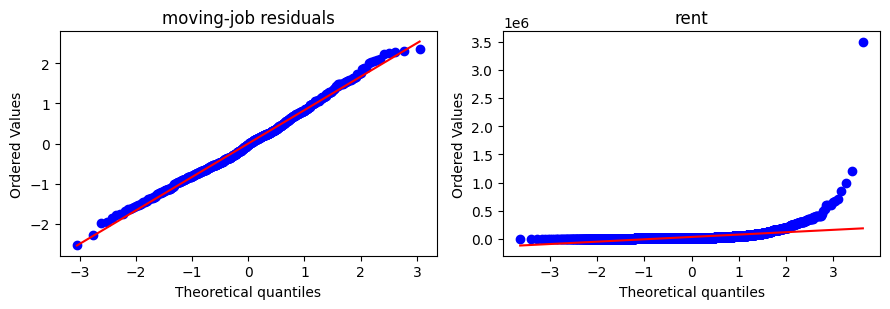

In [16]:
rent = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/rent.csv")
fit4 = smf.ols("hours ~ volume_cuft + crew_size + stairs_flights + miles + packing_service",
               data=jobs).fit()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
stats.probplot(fit4.resid, dist="norm", plot=axes[0])
axes[0].set_title("moving-job residuals")
stats.probplot(rent.Rent, dist="norm", plot=axes[1])
axes[1].set_title("rent")
plt.tight_layout()
plt.show()

Rent curls up at both ends because a handful of listings cost many times the typical one: the mean of \$35,010 and median of \$16,000 from Unit 1, seen sideways. Try `np.log(rent.Rent)` in the second panel.

## 15. Unit 4's job, refitted

The same model and the same customer as Unit 4: 800 cubic feet, crew of 3, two flights, 12 miles, packing.

In [17]:
job = pd.DataFrame({"volume_cuft": [800], "crew_size": [3], "stairs_flights": [2],
                    "miles": [12], "packing_service": [1]})
pred = fit4.get_prediction(job).summary_frame(alpha=0.05)
pred.round(3)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,12.392,0.073,12.248,12.535,10.743,14.04


In [18]:
y_hat = pred["mean"].iloc[0]
lo, hi = pred.obs_ci_lower.iloc[0], pred.obs_ci_upper.iloc[0]
t_star = stats.t.ppf(0.975, fit4.df_resid)
se_pred = (hi - lo) / (2 * t_star)

print(f"point prediction : {y_hat:.2f} hours")
print(f"95% interval     : {lo:.2f} to {hi:.2f}")
print(f"t*               : {t_star:.4f}")
print(f"so SE_pred       : {se_pred:.4f}")

point prediction : 12.39 hours
95% interval     : 10.74 to 14.04
t*               : 1.9640
so SE_pred       : 0.8393


Unit 4 printed the interval and stopped. Running it backwards recovers the spread, and the spread is the whole forecast: **hours ~ Normal(12.39, 0.839²)**. Every question below is one call to that distribution.

## 16. Where the width comes from



In [19]:
se_line = pred["mean_se"].iloc[0]
resid_sd = np.sqrt(fit4.scale)

print(f"SE_line  (uncertainty about the average job) : {se_line:.4f}")
print(f"sigma    (variation among jobs like it)      : {resid_sd:.4f}")
print(f"sqrt(SE_line^2 + sigma^2)                    : "
      f"{np.sqrt(se_line**2 + resid_sd**2):.4f}")
print(f"SE_pred from the interval                    : {se_pred:.4f}")

SE_line  (uncertainty about the average job) : 0.0732
sigma    (variation among jobs like it)      : 0.8361
sqrt(SE_line^2 + sigma^2)                    : 0.8393
SE_pred from the interval                    : 0.8393


0.073 and 0.836 combine to 0.839. With 600 jobs the first term is almost nothing, so the prediction interval is essentially the residual spread. **More data would shrink SE_line and leave sigma alone**, which is why a prediction interval does not collapse no matter how much data you collect.

## 17. The forecast, used



In [20]:
forecast = norm(y_hat, se_pred)

for threshold in [13, 14, 15]:
    print(f"P(past {threshold} hours): {forecast.sf(threshold):7.4f}"
          f"   (z = {(threshold - y_hat) / se_pred:.2f})")
print(f"90% of such jobs finish within: {forecast.ppf(0.90):.2f} hours")

P(past 13 hours):  0.2342   (z = 0.73)
P(past 14 hours):  0.0276   (z = 1.92)
P(past 15 hours):  0.0009   (z = 3.11)
90% of such jobs finish within: 13.47 hours


The crew earns overtime after 13 hours. The point prediction of 12.39 says there is no overtime on this job; the forecast says **23%** of jobs like it run into some. Those are answers to different questions and the dispatcher needs the second one.

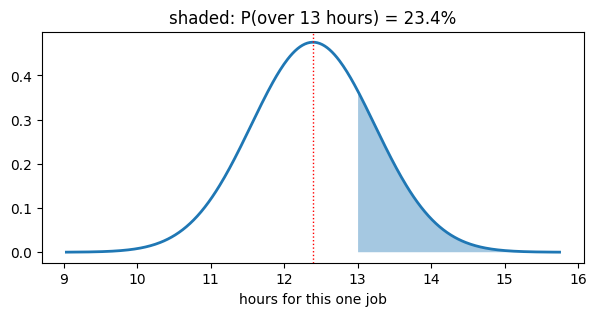

In [21]:
fig, ax = plt.subplots(figsize=(7, 3))
grid = np.linspace(y_hat - 4 * se_pred, y_hat + 4 * se_pred, 400)
ax.plot(grid, forecast.pdf(grid), lw=2)
ax.fill_between(grid, 0, forecast.pdf(grid), where=grid > 13, alpha=0.4)
ax.axvline(y_hat, color="red", ls=":", lw=1)
ax.set_xlabel("hours for this one job")
ax.set_title(f"shaded: P(over 13 hours) = {forecast.sf(13):.1%}")
plt.show()

## 18. Expected overtime cost

Overtime runs $85 an hour past 13 hours.

In [22]:
RATE, CUTOFF = 85, 13

print("cost of the point prediction:",
      f"${RATE * max(y_hat - CUTOFF, 0):.2f}")

z = (CUTOFF - y_hat) / se_pred
exact = se_pred * norm.pdf(z) - (CUTOFF - y_hat) * norm.sf(z)
print("expected overtime, exactly  :", f"{exact:.4f} hours = ${RATE * exact:.2f}")

sim = forecast.rvs(200_000, random_state=8)
print("the same thing by simulation:",
      f"${(RATE * np.maximum(sim - CUTOFF, 0)).mean():.2f}")

cost of the point prediction: $0.00
expected overtime, exactly  : 0.1149 hours = $9.77
the same thing by simulation: $9.72


The point prediction gives \$0 and the distribution gives \$9.77, with the simulation a few cents off it on 200,000 draws. This is Unit 7's E[g(Y)] != g(E[Y]) with money attached: the cost rule has a kink at 13 hours, so plugging in the average loses the thing you are paying for. Across a thousand bookings that is about \$9,800. The simulation is there because the exact formula runs out as soon as the pricing rule gets any more complicated, and the simulation does not.

## 19. Three jobs: variances add



In [23]:
total_mean = 3 * y_hat
right = se_pred * np.sqrt(3)
wrong = 3 * se_pred

print(f"E[total]                    : {total_mean:.2f} hours")
print(f"SD, adding variances        : {right:.2f}   P(over 40) = "
      f"{norm.sf(40, total_mean, right):.3f}")
print(f"SD, adding SDs instead      : {wrong:.2f}   P(over 40) = "
      f"{norm.sf(40, total_mean, wrong):.3f}")

E[total]                    : 37.17 hours
SD, adding variances        : 1.45   P(over 40) = 0.026
SD, adding SDs instead      : 2.52   P(over 40) = 0.131


2.6% against 13%, a factor of five, from one wrong addition. Independence is doing work here: three jobs on the same truck in the same weather do not have independent delays, and the real spread would sit between these two numbers.

## 20. Unit 5's logged model: median and mean



In [24]:
dia = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/diamonds.csv")
fit5 = smf.ols("np.log(price) ~ np.log(carat) + C(cut) + C(color) + C(clarity)",
               data=dia).fit()
print("intercept    :", round(fit5.params["Intercept"], 2))
print("log(carat)   :", round(fit5.params["np.log(carat)"], 2))
print("residual sd  :", round(np.sqrt(fit5.scale), 4))

intercept    : 7.9
log(carat)   : 1.88
residual sd  : 0.1347


In [25]:
stone = pd.DataFrame({"carat": [1.0], "cut": ["Ideal"], "color": ["G"],
                      "clarity": ["VS2"]})
p5 = fit5.get_prediction(stone).summary_frame(alpha=0.05)
log_yhat, sig = p5["mean"].iloc[0], np.sqrt(fit5.scale)

print(f"prediction on the log scale : {log_yhat:.3f}")
print(f"exp(yhat), the MEDIAN       : ${np.exp(log_yhat):,.0f}")
print(f"the MEAN, exp(yhat+sig^2/2) : ${np.exp(log_yhat + sig**2 / 2):,.0f}")
print(f"95% interval                : ${np.exp(p5.obs_ci_lower.iloc[0]):,.0f}"
      f" to ${np.exp(p5.obs_ci_upper.iloc[0]):,.0f}")
print(f"P(over $6,000)              : "
      f"{lognorm.sf(6000, s=sig, scale=np.exp(log_yhat)):.3f}")

prediction on the log scale : 8.602
exp(yhat), the MEDIAN       : $5,443
the MEAN, exp(yhat+sig^2/2) : $5,492
95% interval                : $4,179 to $7,089
P(over $6,000)              : 0.235


7.90 and 1.88 are Unit 5's printed coefficients, reproduced here. The interval is symmetric on the log scale and lopsided after exponentiating, which is correct and is why you exponentiate the endpoints rather than building an interval around \$5,443. `lognorm`'s `scale` argument is `exp(mu)`, not `mu`; that is the one place this gets people.

## 21. How far the mean sits above the median



In [26]:
pd.DataFrame({"sigma": np.round([sig, 0.2, 0.4, 0.6, 0.8], 3)}).assign(
    mean_over_median=lambda d: np.exp(d.sigma**2 / 2).round(3))

,sigma,mean_over_median
0,0.135,1.009
1,0.200,1.020
2,0.400,1.083
3,0.600,1.197
4,0.800,1.377


At Unit 5's sigma of 0.135 the gap is 0.9% and you can ignore it. The rule still matters, because at 0.8 the mean is 38% above the median and a budget built on the median would be short by that much. Quote the median to one customer, budget the mean for a thousand.

## 22. Where the forecast needs more work

Everything above assumed normal residuals with constant spread. Both are checkable.

In [27]:
quartile = pd.qcut(fit4.fittedvalues, 4)
fit4.resid.groupby(quartile, observed=True).std().round(3)

(2.1910000000000003, 8.533]    0.884
(8.533, 10.422]                0.797
(10.422, 12.198]               0.768
(12.198, 18.722]               0.826
dtype: float64

Four roughly equal numbers, so one residual SD for all jobs is defensible here. If they climbed, the single `se_pred` above would be too narrow for big jobs and too wide for small ones.

In [28]:
big = job.assign(volume_cuft=2000)
print("the data run from", jobs.volume_cuft.min(), "to", jobs.volume_cuft.max(), "cubic feet")
fit4.get_prediction(big).summary_frame(alpha=0.05).round(2)

the data run from 120 to 1317 cubic feet


,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,27.34,0.21,26.93,27.76,25.65,29.04


A 2,000 cubic foot job is half again as large as anything in the data, and the software returns a confident-looking interval for it without complaint. Nothing in the output tells you that you have left the data behind.

## 23. The whole thing as one function

Every forecast in this notebook was these four lines.

In [29]:
def forecast_for(fit, new_row, level=0.95):
    """The predictive distribution for one new case, as a frozen normal."""
    frame = fit.get_prediction(new_row).summary_frame(alpha=1 - level)
    width = frame.obs_ci_upper.iloc[0] - frame.obs_ci_lower.iloc[0]
    t_star = stats.t.ppf(1 - (1 - level) / 2, fit.df_resid)
    return norm(frame["mean"].iloc[0], width / (2 * t_star))


f = forecast_for(fit4, job)
print("P(over 13 hours)    :", round(f.sf(13), 4))
print("the 90th percentile :", round(f.ppf(0.90), 2))
print("the middle 50%      :", f.ppf([0.25, 0.75]).round(2))
print("E[overtime cost]    :",
      round(85 * np.maximum(f.rvs(200_000, random_state=0) - 13, 0).mean(), 2))

P(over 13 hours)    : 0.2342
the 90th percentile : 13.47
the middle 50%      : [11.83 12.96]
E[overtime cost]    : 9.76


A prediction interval answers one question. The distribution behind it answers any question you can phrase as an area, which includes the ones a dispatcher actually asks.